# Strategy Analyst Case Study Code

## Step 1: read in CSV

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raw_MSA_data_path = os.environ.get('MSA_DOWNLOAD_PATH')

# Convert to pandas DataFrame
MSA_data = pd.read_excel(raw_MSA_data_path)
print(MSA_data.head())

             MSA  BEV_GROWTH_RATE  CURRENT_EVGO_SHARE  COMPETITOR_DENSITY  \
0    Los Angeles               18                  12                   9   
1  San Francisco               15                   8                  10   
2        Phoenix               12                  20                   6   
3         Dallas               14                  10                   7   
4        Atlanta               11                   5                   5   

   CAPEX_PER_STALL  EXPECTED_MARGIN  FORECAST_TSD  
0             0.40             0.28           250  
1             0.55             0.32           300  
2             0.25             0.24           180  
3             0.30             0.27           220  
4             0.28             0.26           210  


## Step 2: exploratory analysis, plotting all 6 variables across each market

### EV growth rate highest in coastal cities

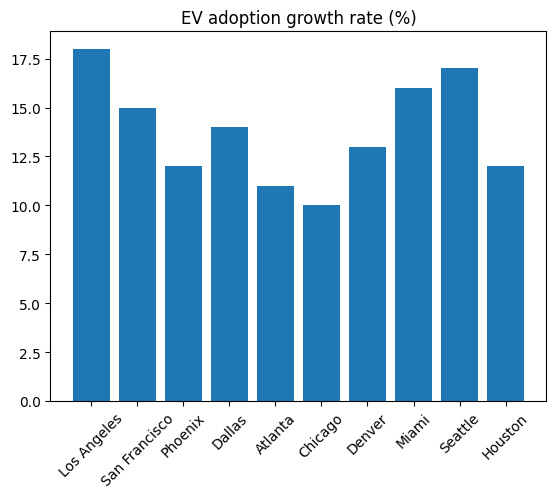

In [19]:
plt.bar(MSA_data['MSA'],MSA_data['BEV_GROWTH_RATE'])
plt.xticks(rotation=45)
plt.title("EV adoption growth rate (%)")
plt.show()

### EVgo has high market share (>= 20%) in Denver and Phoenix

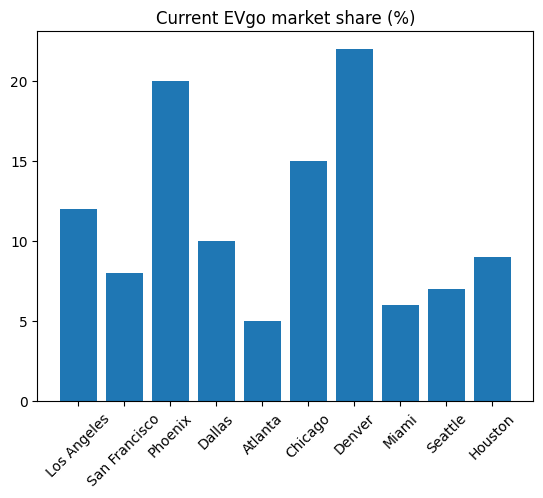

In [20]:
plt.bar(MSA_data['MSA'],MSA_data['CURRENT_EVGO_SHARE'])
plt.xticks(rotation=45)
plt.title("Current EVgo market share (%)")
plt.show()

### Competition highest in California

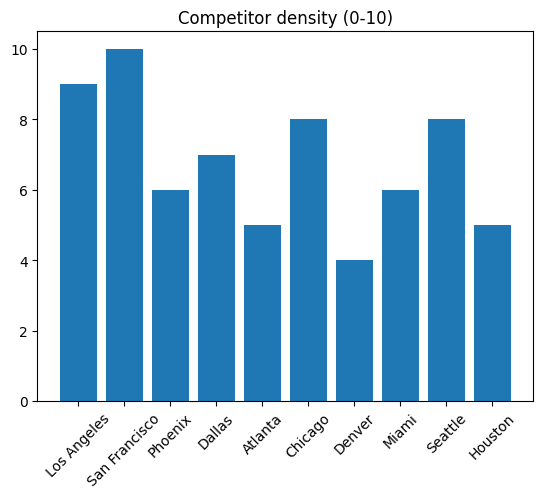

In [21]:
plt.bar(MSA_data['MSA'],MSA_data['COMPETITOR_DENSITY'])
plt.xticks(rotation=45)
plt.title("Competitor density (0-10)")
plt.show()

### Capex highest in California and Seattle

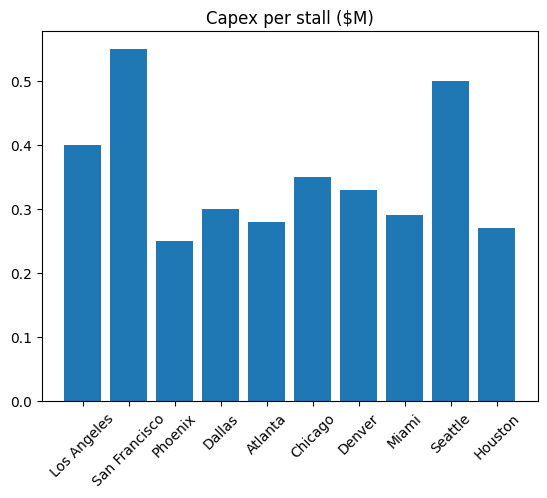

In [22]:
plt.bar(MSA_data['MSA'],MSA_data['CAPEX_PER_STALL'])
plt.xticks(rotation=45)
plt.title("Capex per stall ($M)")
plt.show()

### Expected margin highest in California, Seattle, and Miami but relatively even across the board

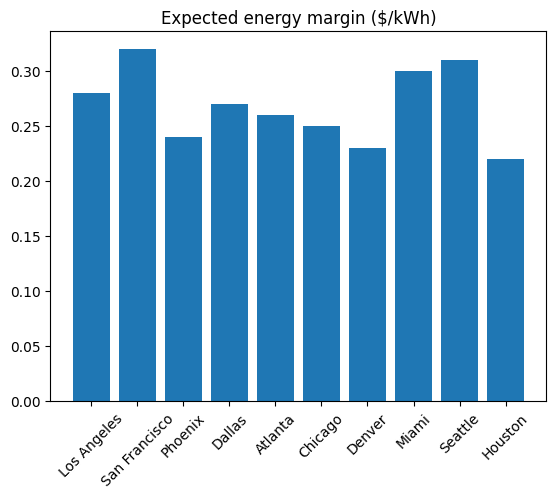

In [23]:
plt.bar(MSA_data['MSA'],MSA_data['EXPECTED_MARGIN'])
plt.xticks(rotation=45)
plt.title("Expected energy margin ($/kWh)")
plt.show()

### Throughput per stall also highest in California, Seattle and Miami with a bit more separation between high and low

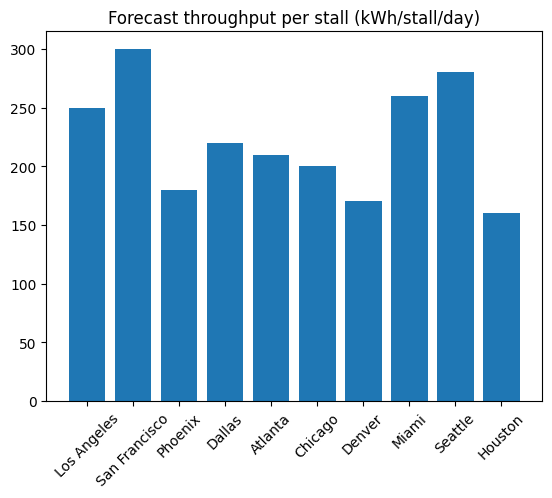

In [24]:
plt.bar(MSA_data['MSA'],MSA_data['FORECAST_TSD'])
plt.xticks(rotation=45)
plt.title("Forecast throughput per stall (kWh/stall/day)")
plt.show()

## Step 3: calculations and tables

In [ ]:
# assuming 20 stalls per project 
stalls = 20

# create new column for capex per project to determine how many projects we can afford to install
MSA_data['CAPEX_PER_PROJECT'] = MSA_data['CAPEX_PER_STALL'] * stalls

# creating column for expected gross margin ($ per stall per day)
MSA_data['EXPECTED_GROSS_MARGIN_PER_STALL'] = MSA_data['EXPECTED_MARGIN'] * MSA_data['FORECAST_TSD']

# creating column for annual expected gross margin ($ per stall per year)
MSA_data['ANNUAL_EXPECTED_GROSS_MARGIN_PER_STALL'] = MSA_data['EXPECTED_GROSS_MARGIN_PER_STALL'] * 365

# creating a column for payback estimate (years) from ($ per stall) and ($ per stall per year)
MSA_data['PAYBACK'] = (MSA_data['CAPEX_PER_STALL'] * 1000000) / MSA_data['ANNUAL_EXPECTED_GROSS_MARGIN_PER_STALL']



In [ ]:
# creating function to calculate total allocation given city and project count

## input: dictionary of city and project count, optional input of uptake scenario flag (defaults to False)
## output: total cost of allocation in millions of dollars

def cost_allocator(city_project_dictionary, uptake=False):

    total_cost = 0

    for city in city_project_dictionary.keys():
        
        if uptake == True:
            # city cost determined by number of projects multiplied by CAPEX_PER_PROJECT for that city
            city_cost = city_project_dictionary[city] * MSA_data.loc[MSA_data['MSA']==city,'CAPEX_PER_PROJECT_UPTAKE'].values[0]
        else:
            city_cost = city_project_dictionary[city] * MSA_data.loc[MSA_data['MSA']==city,'CAPEX_PER_PROJECT'].values[0]

        total_cost += city_cost
    
    return total_cost

In [148]:
# final allocation comes to $46.4 million

city_project_dictionary = {'Miami':1, 'Seattle':1, 'Los Angeles':1, 'Dallas':1, 'Atlanta':1, 'San Francisco':1}

total_allocation = cost_allocator(city_project_dictionary)

print(total_allocation)

46.4


In [109]:
# creating table of final recommendations
pd.set_option('display.precision', 2)

total_allocation_table = MSA_data.loc[MSA_data['MSA'].isin(city_project_dictionary.keys()),['MSA','CAPEX_PER_PROJECT']]
total_allocation_table['NUMBER_OF_PROJECTS'] = 1
total_allocation_table.loc['Total'] = {'MSA':'Total','NUMBER_OF_PROJECTS':total_allocation_table['NUMBER_OF_PROJECTS'].sum(numeric_only=True),'CAPEX_PER_PROJECT':total_allocation_table['CAPEX_PER_PROJECT'].sum(numeric_only=True)}
display(total_allocation_table)

,MSA,CAPEX_PER_PROJECT,NUMBER_OF_PROJECTS
0,Los Angeles,8.00,1
1,San Francisco,11.00,1
3,Dallas,6.00,1
4,Atlanta,5.60,1
7,Miami,5.80,1
8,Seattle,10.00,1
Total,Total,46.40,6


In [112]:
gross_margin_table = MSA_data[['MSA','EXPECTED_GROSS_MARGIN_PER_STALL']].sort_values(by='EXPECTED_GROSS_MARGIN_PER_STALL',ascending=False)
display(gross_margin_table)

,MSA,EXPECTED_GROSS_MARGIN_PER_STALL
1,San Francisco,96.00
8,Seattle,86.80
7,Miami,78.00
0,Los Angeles,70.00
3,Dallas,59.40
4,Atlanta,54.60
5,Chicago,50.00
2,Phoenix,43.20
6,Denver,39.10
9,Houston,35.20


In [149]:
# create new column for annual expected gross margin per project
MSA_data['ANNUAL_EXPECTED_GROSS_MARGIN'] = MSA_data['ANNUAL_EXPECTED_GROSS_MARGIN_PER_STALL'] * stalls

total_annual_gross_margin_table = MSA_data.loc[MSA_data['MSA'].isin(city_project_dictionary.keys()),['MSA','ANNUAL_EXPECTED_GROSS_MARGIN']]
total_annual_gross_margin_table.loc['Total'] = {'MSA':'Total','ANNUAL_EXPECTED_GROSS_MARGIN':total_annual_gross_margin_table['ANNUAL_EXPECTED_GROSS_MARGIN'].sum(numeric_only=True)}
display(total_annual_gross_margin_table)

,MSA,ANNUAL_EXPECTED_GROSS_MARGIN
0,Los Angeles,"511,000.00"
1,San Francisco,"700,800.00"
3,Dallas,"433,620.00"
4,Atlanta,"398,580.00"
7,Miami,"569,400.00"
8,Seattle,"633,640.00"
Total,Total,"3,247,040.00"


In [114]:
payback_table = MSA_data[['MSA','PAYBACK']].sort_values(by='PAYBACK')
display(payback_table)

,MSA,PAYBACK
7,Miami,10.19
3,Dallas,13.84
4,Atlanta,14.05
0,Los Angeles,15.66
1,San Francisco,15.70
8,Seattle,15.78
2,Phoenix,15.85
5,Chicago,19.18
9,Houston,21.01
6,Denver,23.12


In [ ]:
# $30 million scenario

# final allocation comes to $29.8 million

city_project_dictionary = {'Miami':1, 'Seattle':1, 'Los Angeles':1, 'Dallas':1}

total_allocation = cost_allocator(city_project_dictionary)

print(total_allocation)

29.8


In [116]:
total_allocation_table = MSA_data.loc[MSA_data['MSA'].isin(city_project_dictionary.keys()),['MSA','CAPEX_PER_PROJECT']]
total_allocation_table['NUMBER_OF_PROJECTS'] = 1
total_allocation_table.loc['Total'] = {'MSA':'Total','NUMBER_OF_PROJECTS':total_allocation_table['NUMBER_OF_PROJECTS'].sum(numeric_only=True),'CAPEX_PER_PROJECT':total_allocation_table['CAPEX_PER_PROJECT'].sum(numeric_only=True)}
display(total_allocation_table)

,MSA,CAPEX_PER_PROJECT,NUMBER_OF_PROJECTS
0,Los Angeles,8.00,1
3,Dallas,6.00,1
7,Miami,5.80,1
8,Seattle,10.00,1
Total,Total,29.80,4


In [141]:
# aggressive uptake scenario

high_growth_MSAs = ['Los Angeles','Seattle','Miami','San Francisco','Dallas']

# assigning binary to flag top 5 high growth MSAs
MSA_data['HIGH_GROWTH_MSA'] = np.where(MSA_data['MSA'].isin(high_growth_MSAs),1,0)

# doubling TSD for these MSAs
MSA_data['FORECAST_TSD_UPTAKE'] = np.where(MSA_data['HIGH_GROWTH_MSA']==1,MSA_data['FORECAST_TSD']*2,MSA_data['FORECAST_TSD'])

# increasing capex 25% for these MSAs
MSA_data['CAPEX_PER_STALL_UPTAKE'] = np.where(MSA_data['HIGH_GROWTH_MSA']==1,MSA_data['CAPEX_PER_STALL']*1.25,MSA_data['CAPEX_PER_STALL'])

# create new column for capex per project to determine how many projects we can afford to install
MSA_data['CAPEX_PER_PROJECT_UPTAKE'] = MSA_data['CAPEX_PER_STALL_UPTAKE'] * stalls

# creating column for expected gross margin ($ per stall per day)
MSA_data['EXPECTED_GROSS_MARGIN_PER_STALL_UPTAKE'] = MSA_data['EXPECTED_MARGIN'] * MSA_data['FORECAST_TSD_UPTAKE']

# creating column for annual expected gross margin ($ per stall per year)
MSA_data['ANNUAL_EXPECTED_GROSS_MARGIN_PER_STALL_UPTAKE'] = MSA_data['EXPECTED_GROSS_MARGIN_PER_STALL_UPTAKE'] * 365

# creating a column for payback estimate (years) from ($ per stall) and ($ per stall per year)
MSA_data['PAYBACK_UPTAKE'] = (MSA_data['CAPEX_PER_STALL_UPTAKE'] * 1000000) / MSA_data['ANNUAL_EXPECTED_GROSS_MARGIN_PER_STALL_UPTAKE']

In [150]:
# final allocation for uptake scenario comes to $49.1 million

#city_project_dictionary_uptake = {'Miami':2, 'Los Angeles':2, 'Dallas':2}
city_project_dictionary_uptake = {'Miami':1, 'Seattle':1, 'Los Angeles':1, 'Atlanta':1, 'San Francisco':1}

total_allocation = cost_allocator(city_project_dictionary_uptake, uptake=True)

print(total_allocation)

49.1


In [151]:
payback_table = MSA_data[['MSA','PAYBACK_UPTAKE']].sort_values(by='PAYBACK_UPTAKE')
display(payback_table)

,MSA,PAYBACK_UPTAKE
7,Miami,6.37
3,Dallas,8.65
0,Los Angeles,9.78
1,San Francisco,9.81
8,Seattle,9.86
4,Atlanta,14.05
2,Phoenix,15.85
5,Chicago,19.18
9,Houston,21.01
6,Denver,23.12


In [152]:
total_allocation_table = MSA_data.loc[MSA_data['MSA'].isin(city_project_dictionary_uptake.keys()),['MSA','CAPEX_PER_PROJECT_UPTAKE']]
total_allocation_table['NUMBER_OF_PROJECTS'] = 1
total_allocation_table.loc['Total'] = {'MSA':'Total','NUMBER_OF_PROJECTS':total_allocation_table['NUMBER_OF_PROJECTS'].sum(numeric_only=True),'CAPEX_PER_PROJECT_UPTAKE':total_allocation_table['CAPEX_PER_PROJECT_UPTAKE'].sum(numeric_only=True)}
display(total_allocation_table)

,MSA,CAPEX_PER_PROJECT_UPTAKE,NUMBER_OF_PROJECTS
0,Los Angeles,10.00,1
1,San Francisco,13.75,1
4,Atlanta,5.60,1
7,Miami,7.25,1
8,Seattle,12.50,1
Total,Total,49.10,5
